# Online ("self") reinforcement learning for LLMs, step by step 🔁
### The model writes its own training data: sample → score → compare within the group → update (GRPO), for autoregressive *and* diffusion LLMs

Supervised fine-tuning copies answers someone else wrote. **Online RL** lets the model *practise*.
For each prompt it samples several answers **from its current self**. A reward says which were good,
and the model shifts probability toward those. Then it samples again from the improved model, and
repeats. The data are generated on-policy, *by the learner itself*, as training goes on.

"Self" covers two increasingly autonomous ideas, and this notebook builds and tests both:

| | who writes the training data | who judges it | example methods |
|---|---|---|---|
| SFT | humans / a teacher model | (labels are the target) | instruction tuning |
| offline preference learning | a fixed dataset of pairs | humans / a reward model, once | DPO |
| **online RL, verifiable reward** | **the policy itself, every step** | a checker (unit tests, exact answer) | PPO, **GRPO** (DeepSeek-R1), RLVR |
| **online RL, self-reward** | **the policy itself** | **the policy itself** (majority vote, its own judgement) | **TTRL**, self-rewarding LMs |

Everything below runs **for real on a CPU in about three minutes**. The models are this repo's
autoregressive and masked-diffusion LMs (`hale_llm.models`), trained by the RL package
`hale_llm.rl`, and every animation is rendered from the recorded run.

| § | Question |
|---|---|
| 1 | What does the online loop look like? |
| 2 | Setup, config (YAML with inheritance) and the registries |
| 3 | The task and the warm-start policy: what does it know before RL? |
| 4 | The maths: policy gradient → REINFORCE → group baseline (GRPO) → clipping → KL |
| 5 | Run online GRPO with a verifiable reward, and watch the policy change |
| 6 | Why exploration decides everything (temperature, over-confident SFT) |
| 7 | Self-reward without labels (majority vote): what it can and cannot do |
| 8 | Diffusion LLMs: no exact log-likelihood, so how do you do policy gradients? (d1) |
| 9 | Pitfalls checklist, summary, references |

## 1. The online loop

```mermaid
flowchart LR
  P["prompt batch<br/>(from the pool)"]:::io --> S["<b>sample</b> G answers per prompt<br/>from the CURRENT policy π_θ<br/>(temperature > 1)"]:::pol
  S --> R["<b>score</b><br/>verifier r ∈ {0,1}<br/>or self-reward (majority)"]:::rew
  R --> A["<b>normalise in the group</b><br/>A = (r − mean) / std"]:::adv
  A --> U["<b>update</b> θ<br/>clipped policy gradient<br/>+ β·KL(π_θ ‖ π_ref)"]:::upd
  U -- "next step samples from the<br/>improved policy (on-policy)" --> S
  REF["π_ref = warm-start copy<br/>(frozen)"]:::io -.-> U
  classDef io fill:#1e293b,stroke:#64748b,color:#fff
  classDef pol fill:#0c3b4a,stroke:#22d3ee,color:#fff
  classDef rew fill:#3b2f0b,stroke:#fbbf24,color:#fff
  classDef adv fill:#2e1f57,stroke:#a78bfa,color:#fff
  classDef upd fill:#0f3d2c,stroke:#34d399,color:#fff
```

The difference from supervised learning is the loop: the **data distribution moves with the model**.
Whatever the model cannot sample, it cannot learn from. Section 6 shows how decisive that is.

## 2. Setup

The cell below makes `src/` importable (and a sibling `HaleBlocks/src`, where the registries live),
quietens logging, and creates the output folder for the animations.

In [1]:
import copy, sys, time, warnings
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "hale_llm").is_dir())
for src in (ROOT.parent / "HaleBlocks" / "src", ROOT / "src"):
    if src.is_dir() and str(src) not in sys.path:
        sys.path.insert(0, str(src))
FILMS = ROOT / "assets" / "rl"
CONFIGS = ROOT / "configs" / "rl"

from loguru import logger
logger.remove(); logger.add(sys.stderr, level="WARNING")
warnings.filterwarnings("ignore")

from hale_llm.rl import (OnlineRLConfig, OnlineRLExperiment, GroupRelativeAdvantage, GRPOObjective,
                         MajorityVoteReward, REWARDS, LOG_PROB_ESTIMATORS)
from hale_llm.visualization.rl_films import GRPOStepFilm, PolicyEvolutionFilm, DiffusionLogProbFilm

COL = {"seen": "#2DD4BF", "unseen": "#FBBF24", "reward": "#22D3EE", "bad": "#F87171", "muted": "#8494B0"}
plt.rcParams.update({"figure.facecolor": "#0B1220", "axes.facecolor": "#0B1220", "axes.edgecolor": "#8494B0",
                     "axes.labelcolor": "#E6EDF7", "text.color": "#E6EDF7", "xtick.color": "#8494B0",
                     "ytick.color": "#8494B0", "axes.titleweight": "bold", "legend.frameon": False})
torch.manual_seed(0)

### The configuration: YAML with `inherits:`

Every experiment in `configs/rl/` inherits `base.yaml` and overrides only what differs, so the AR,
self-reward and diffusion runs below differ by **one or two lines each**. `OnlineRLConfig` resolves
chains of any depth (and rejects cycles), then validates every field with pydantic.

In [2]:
for name in ["base.yaml", "arithmetic_autoregressive.yaml", "arithmetic_self_reward.yaml", "arithmetic_diffusion.yaml"]:
    text = (CONFIGS / name).read_text()
    print(f"── configs/rl/{name} " + "─" * (60 - len(name)))
    print(text if name != "base.yaml" else "\n".join(text.splitlines()[:40]))

cfg = OnlineRLConfig.from_yaml(CONFIGS / "arithmetic_self_reward.yaml")
print("resolved self-reward config: variant =", cfg.variant, "| reward =", cfg.reward.type,
      "| steps =", cfg.train.steps, "| temperature =", cfg.rollout.temperature)

── configs/rl/base.yaml ───────────────────────────────────────────────────
# Online RL (GRPO) on the toy arithmetic task. Every other file here `inherits:` this one and
# overrides only what differs. Loaded by hale_llm.rl.OnlineRLConfig.from_yaml.
variant: autoregressive
seed: 0
model: {d_model: 96, n_heads: 4, n_layers: 3, d_ff: 256}
task:
  name: arithmetic
  max_operand: 9        # a, b in 0..9 -> 100 facts
  sft_fraction: 0.4     # 40 facts in the supervised warm start; 60 must be found by RL
sft:
  steps: 60             # short on purpose: a confident SFT model stops exploring
  lr: 3.0e-3
rollout:
  group_size: 8         # G samples per prompt (the GRPO baseline is their mean reward)
  prompts_per_step: 16
  temperature: 1.5      # exploration; at 1.0 most groups have zero reward variance
  sampling_steps: 2     # diffusion only: denoising steps for a 2-token answer
grpo:
  lr: 5.0e-4
  inner_epochs: 2       # gradient steps per rollout batch (PPO-style reuse, clipped)
  clip_ep

## 3. The task and the warm-start policy

The environment is deliberately tiny, so every number can be inspected:

* **prompt** `"a+b="` with `a, b ∈ 0…9` (100 facts), **answer** two digits (`"8+4=" → "12"`);
* the **verifier** checks the answer exactly; that is the *verifiable reward* of RLVR;
* the **warm start** is a short supervised fine-tune on **40 %** of the facts, which teaches the
  format and some arithmetic. The other 60 facts were never shown with an answer: RL has to find them.

This mirrors the real recipe (DeepSeek-R1, Tülu 3, …): SFT gives a policy that *can* produce good
answers sometimes, and RL turns "sometimes" into "reliably".

In [3]:
exp = OnlineRLExperiment.from_yaml(CONFIGS / "arithmetic_autoregressive.yaml")
task, tok = exp.task, exp.tokenizer
t0 = time.time()
warm = exp.warm_start()                                   # supervised warm start (60 steps, 40 facts)
print(f"warm start: {time.time() - t0:.1f}s | {sum(p.numel() for p in warm.parameters()):,} parameters")
print(f"{len(task.seen_prompts)} facts seen in SFT, {len(task.unseen_prompts)} unseen; example: "
      f"{task.sft_texts[0]!r}")
print("registered rewards:", sorted(REWARDS), "| log-prob estimators:", sorted(LOG_PROB_ESTIMATORS))
base = exp.evaluate(warm, 0)
print(f"greedy accuracy before RL: seen {base['seen']:.0%}, unseen {base['unseen']:.0%}, all {base['all']:.0%}")

warm start: 0.2s | 271,584 parameters
40 facts seen in SFT, 60 unseen; example: '2+3=05'
registered rewards: ['exact_match', 'majority_vote'] | log-prob estimators: ['autoregressive', 'diffusion']
greedy accuracy before RL: seen 45%, unseen 3%, all 20%


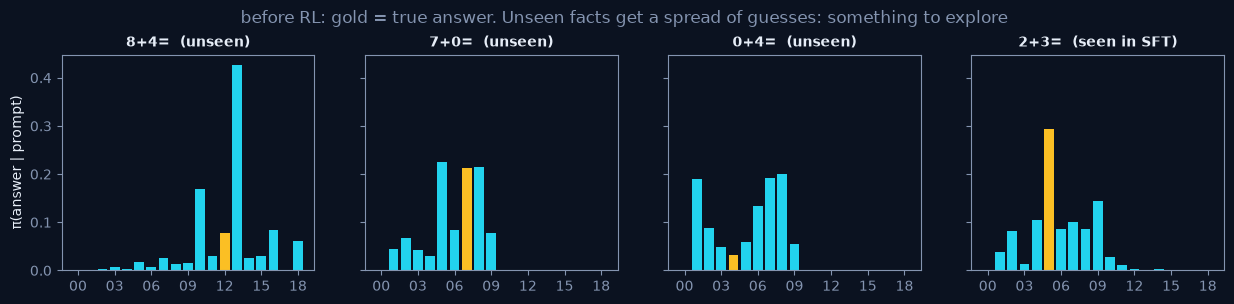

In [4]:
estimator = exp.log_prob()
show = task.unseen_prompts[:3] + task.seen_prompts[:1]
fig, axes = plt.subplots(1, len(show), figsize=(15, 2.8), sharey=True)
for ax, prompt in zip(axes, show):
    dist = estimator.answer_distribution(warm, prompt, task.candidates)[:19]
    colours = [COL["unseen"] if c == task.answers[prompt] else COL["reward"] for c in task.candidates[:19]]
    ax.bar(range(19), dist, color=colours)
    ax.set_xticks(range(0, 19, 3), task.candidates[0:19:3])
    seen = "seen in SFT" if prompt in task.seen_prompts else "unseen"
    ax.set_title(f"{prompt}  ({seen})", fontsize=10)
axes[0].set_ylabel("π(answer | prompt)")
fig.suptitle("before RL: gold = true answer. Unseen facts get a spread of guesses: something to explore",
             color=COL["muted"], y=1.04)
plt.show()

## 4. The maths, one idea at a time

**Objective.** Maximise the expected reward of the policy's own samples:
$$J(\theta) = \mathbb{E}_{x\sim\mathcal{D}}\;\mathbb{E}_{y\sim\pi_\theta(\cdot\mid x)}\big[r(x,y)\big].$$

**Policy gradient (log-derivative trick).** The sampling distribution depends on $\theta$, and
$\nabla\pi = \pi\,\nabla\log\pi$ turns the gradient into an expectation we can sample:
$$\nabla_\theta J = \mathbb{E}\big[r(x,y)\,\nabla_\theta \log \pi_\theta(y\mid x)\big],
\qquad \log\pi_\theta(y\mid x)=\sum_k \log\pi_\theta(y_k\mid x, y_{<k}).$$
That is **REINFORCE** (Williams, 1992): sample, then push up the log-probability of each sample in
proportion to its reward.

**Baseline.** Subtracting any $b(x)$ that does not depend on $y$ leaves the gradient unbiased, since
$\mathbb{E}[\nabla\log\pi]=0$, but can cut its variance dramatically. PPO learns $b$ with a value
network (a critic). **GRPO** (DeepSeekMath; Shao et al., 2024) samples $G$ answers per prompt and uses
**their own mean**:
$$A_i = \frac{r_i - \operatorname{mean}(r_1..r_G)}{\operatorname{std}(r_1..r_G) + \varepsilon}.$$
No critic is needed, and the baseline is exactly on-policy. Answers *better than their siblings* go up;
worse ones go down.

**Clipping.** To reuse one batch of samples for a few gradient steps (`inner_epochs`), weight each
token by the ratio $\rho = \pi_\theta / \pi_{\text{old}}$, and **clip** it so that one batch cannot move
the policy too far (PPO; Schulman et al., 2017):
$$\mathcal{L}_{\text{clip}} = -\min\big(\rho A,\ \operatorname{clip}(\rho, 1-\epsilon, 1+\epsilon)\,A\big).$$

**KL anchor.** $\beta\,\mathrm{KL}(\pi_\theta\,\|\,\pi_{\text{ref}})$ keeps the policy near the warm
start. It is estimated per token with the non-negative "k3" estimator
$e^{\Delta}-\Delta-1$, $\Delta=\log\pi_{\text{ref}}-\log\pi_\theta$.

The cells below make each piece concrete, using the classes the trainer uses.

In [5]:
# A real group: one prompt, G = 8 answers sampled from the warm-start policy at temperature 1.5.
# We take the first unseen prompt whose group mixes right and wrong answers (a group with equal rewards
# has all-zero advantages, which is the case shown at the end of this cell).
trainer = exp.trainer(copy.deepcopy(warm))
torch.manual_seed(1)
for candidate in task.unseen_prompts:
    batch = trainer.collect([candidate])
    if 0 < batch.rewards.sum() < len(batch.rewards):
        break
prompt, answers, rewards, advantages = batch.group(0)
print(f"prompt {prompt!r}, true answer {task.answers[prompt]!r}")
print(f"{'answer':>8} {'reward':>7} {'advantage':>10}")
for a, r, adv in zip(answers, rewards, advantages):
    print(f"{a:>8} {r:>7.0f} {adv:>+10.3f}")
print(f"mean reward {np.mean(rewards):.3f}; the advantages sum to {sum(advantages):+.1e} "
      "(the group baseline removes the common part)")

flat = torch.tensor([1.0] * 8)
print("\nall answers correct → advantages", GroupRelativeAdvantage()(flat, 8).tolist(),
      "→ no gradient: a solved prompt stops contributing")

prompt '7+0=', true answer '07'
  answer  reward  advantage
      05       0     -0.724
      02       0     -0.724
      07       1     +1.207
      07       1     +1.207
      06       0     -0.724
      03       0     -0.724
      07       1     +1.207
      01       0     -0.724
mean reward 0.375; the advantages sum to +3.0e-07 (the group baseline removes the common part)

all answers correct → advantages [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0] → no gradient: a solved prompt stops contributing


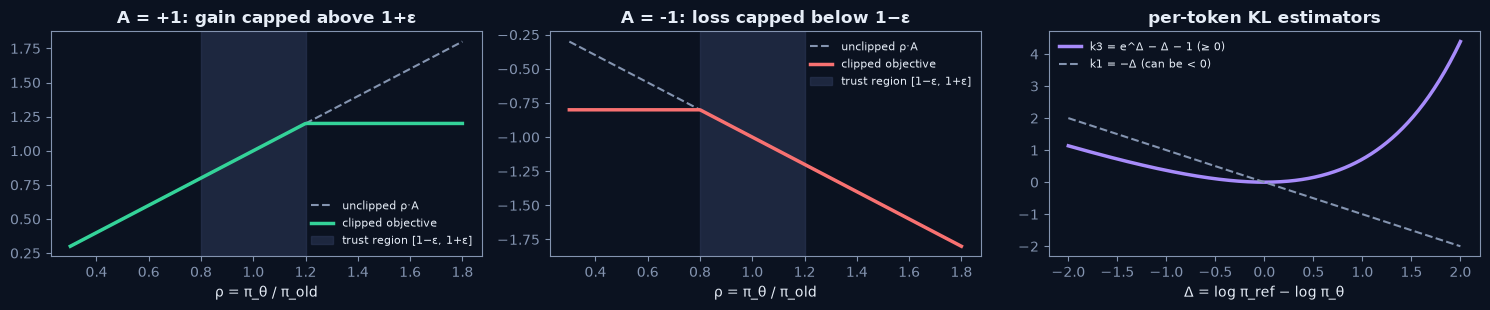

In [6]:
# The clipped surrogate as a function of the ratio ρ, and the k3 KL estimator.
rho = torch.linspace(0.3, 1.8, 300)
obj = GRPOObjective(clip_eps=0.2, kl_coef=0.0)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, A, colour in [(axes[0], 1.0, "#34D399"), (axes[1], -1.0, COL["bad"])]:
    surrogate = [-obj(torch.log(r).view(1, 1), torch.zeros(1, 1), torch.tensor([A])).loss.item() for r in rho]
    ax.plot(rho, rho * A, "--", color=COL["muted"], label="unclipped ρ·A")
    ax.plot(rho, surrogate, color=colour, lw=2.5, label="clipped objective")
    ax.axvspan(0.8, 1.2, color="#2A3654", alpha=0.6, label="trust region [1−ε, 1+ε]")
    ax.set(title=f"A = {A:+.0f}: " + ("gain capped above 1+ε" if A > 0 else "loss capped below 1−ε"),
           xlabel="ρ = π_θ / π_old"); ax.legend(fontsize=8)
d = torch.linspace(-2, 2, 300)
axes[2].plot(d, d.exp() - d - 1, color="#A78BFA", lw=2.5, label="k3 = e^Δ − Δ − 1 (≥ 0)")
axes[2].plot(d, -d, "--", color=COL["muted"], label="k1 = −Δ (can be < 0)")
axes[2].set(title="per-token KL estimators", xlabel="Δ = log π_ref − log π_θ"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [7]:
# Sanity check of the theory on the real model: at ρ = 1 (first inner step), the gradient of the GRPO
# loss equals the REINFORCE-with-baseline gradient  −mean_i A_i · mean_k ∇ log π(y_ik).
policy = copy.deepcopy(warm)
lp = estimator(policy, batch.prompt_ids, batch.completion_ids)
loss = GRPOObjective(clip_eps=0.2, kl_coef=0.0)(lp, lp.detach(), batch.advantages).loss
g_grpo = torch.autograd.grad(loss, list(policy.parameters()), retain_graph=True)
reinforce = -(batch.advantages[:, None] * lp).mean(1).mean()
g_reinforce = torch.autograd.grad(reinforce, list(policy.parameters()))
err = max((a - b).abs().max().item() for a, b in zip(g_grpo, g_reinforce))
print(f"max |∇GRPO − ∇REINFORCE| at ρ = 1: {err:.1e}  ✅" if err < 1e-6 else f"mismatch {err}")

max |∇GRPO − ∇REINFORCE| at ρ = 1: 0.0e+00  ✅


## 5. Run online GRPO with a verifiable reward

`OnlineRLExperiment.run` repeats the loop of §1 for 1000 steps. Each step samples 16 prompts × 8 answers
from the current policy, scores them with the verifier, and runs 2 clipped updates. It records
accuracy every 50 steps and the answer distribution of three tracked *unseen* prompts.

In [8]:
t0 = time.time()
policy_ar = copy.deepcopy(warm)
hist_ar = exp.run(policy_ar)
print(f"{len(hist_ar.stats)} RL steps in {time.time() - t0:.0f}s")
first, last = hist_ar.evals[0], hist_ar.evals[-1]
print(f"greedy accuracy  seen: {first['seen']:.0%} → {last['seen']:.0%}   "
      f"unseen: {first['unseen']:.0%} → {last['unseen']:.0%}   all: {first['all']:.0%} → {last['all']:.0%}")

1000 RL steps in 26s
greedy accuracy  seen: 45% → 98%   unseen: 3% → 92%   all: 20% → 94%


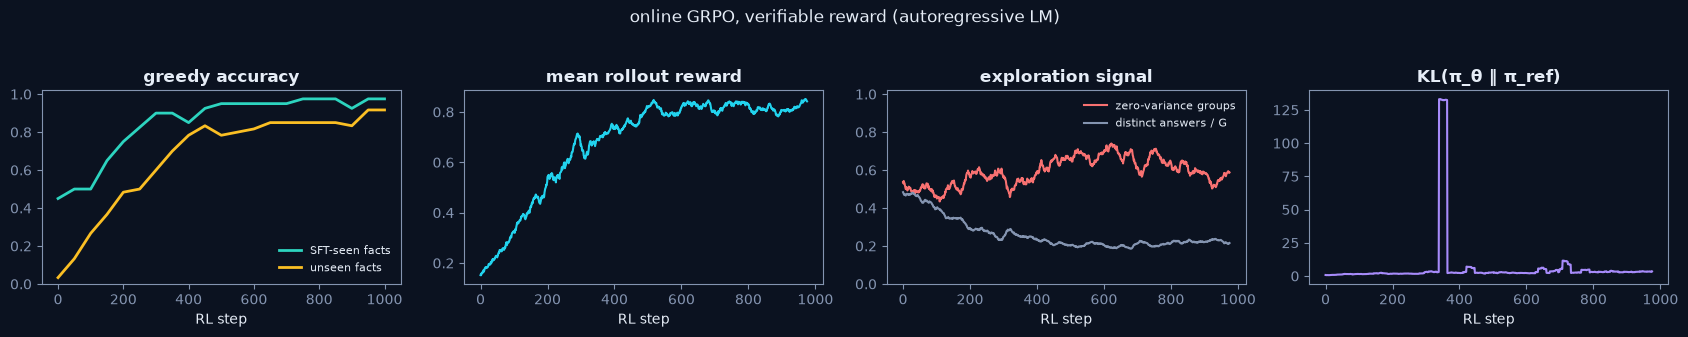

In [9]:
def smooth(x, k=25):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(k) / k, mode="valid") if len(x) > k else x

def curves(hist, title):
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
    steps = [e["step"] for e in hist.evals]
    axes[0].plot(steps, [e["seen"] for e in hist.evals], color=COL["seen"], lw=2, label="SFT-seen facts")
    axes[0].plot(steps, [e["unseen"] for e in hist.evals], color=COL["unseen"], lw=2, label="unseen facts")
    axes[0].set(title="greedy accuracy", xlabel="RL step", ylim=(0, 1.02)); axes[0].legend(fontsize=8)
    axes[1].plot(smooth(hist.series("reward_mean")), color=COL["reward"]); axes[1].set(title="mean rollout reward", xlabel="RL step")
    axes[2].plot(smooth(hist.series("zero_variance_fraction")), color=COL["bad"], label="zero-variance groups")
    axes[2].plot(smooth(hist.series("unique_answers")) / 8, color=COL["muted"], label="distinct answers / G")
    axes[2].set(title="exploration signal", xlabel="RL step", ylim=(0, 1.02)); axes[2].legend(fontsize=8)
    axes[3].plot(smooth(hist.series("kl")), color="#A78BFA"); axes[3].set(title="KL(π_θ ‖ π_ref)", xlabel="RL step")
    fig.suptitle(title, y=1.04); plt.tight_layout(); plt.show()

curves(hist_ar, "online GRPO, verifiable reward (autoregressive LM)")

**Reading the curves.**

* Accuracy on the **unseen** facts climbs from near zero. The model was never told those answers; it
  sampled them, the verifier said "yes", and GRPO made them more likely.
* **Zero-variance groups** rise as prompts get solved: when all 8 answers are right, $A = 0$ and the
  prompt stops producing a gradient. Late in training, the learning signal comes only from the prompts
  the model still gets *sometimes* right.
* **KL** stays small most of the time, with occasional **spikes**. The k3 estimator contains
  $e^{\Delta}$, so a token the reference liked but the policy now almost never produces
  ($\pi_\theta \ll \pi_{\text{ref}}$) gives a huge per-token value. Such spikes are a known
  property of per-token KL estimates; large-scale recipes clip the log-ratio, use a small β, or drop the
  KL term once the reward is verifiable.

### One GRPO step, animated (real rollouts from step 0)

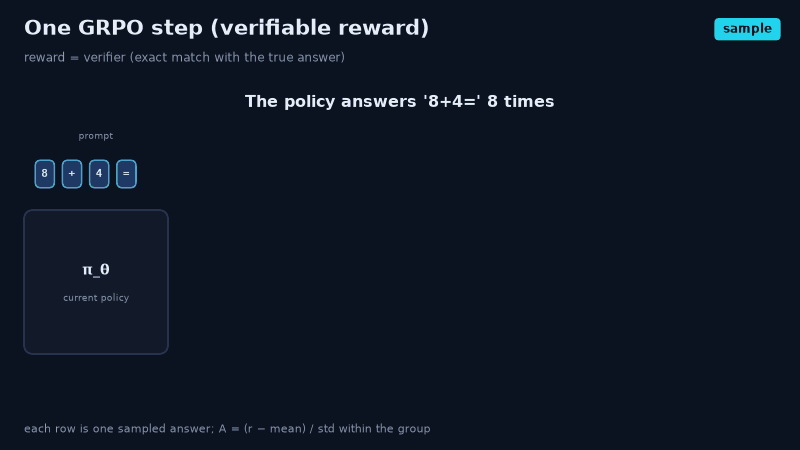

In [10]:
prompt0 = hist_ar.tracked_prompts[0]
film = GRPOStepFilm(*hist_ar.groups[0], title="One GRPO step (verifiable reward)")
display(Image(filename=str(film.render(FILMS / "grpo_step.gif")), embed=True))

### The policy's beliefs over 1000 steps

Each bar is $\pi(\text{answer}\mid\text{prompt})$ for one *unseen* prompt, recorded every 50 steps.
The right panel shows greedy accuracy over the same steps. Probability mass that starts spread over
plausible guesses moves onto the answer the verifier accepted.

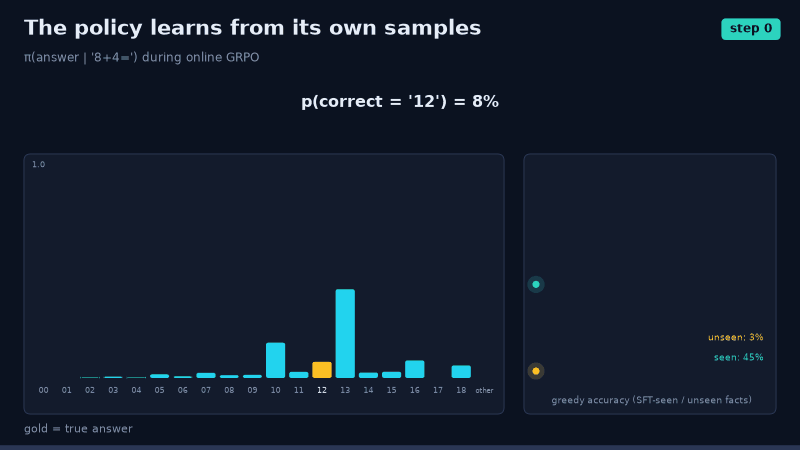

In [11]:
film = PolicyEvolutionFilm.from_history(hist_ar, prompt0, task.answers[prompt0])
display(Image(filename=str(film.render(FILMS / "policy_evolution.gif")), embed=True))

## 6. Exploration decides what can be learned

Policy gradients only reinforce what the policy **actually samples**. Two things kill exploration:

* a **cold sampling temperature** (1.0 instead of 1.5): the model keeps sampling its favourite answer;
* an **over-confident warm start** (150 SFT steps instead of 60): wrong answers on unseen facts become
  near-deterministic.

In both cases, most groups contain 8 copies of the *same* answer. With equal rewards the advantages are
0, and there is no gradient, however long you train. Each ablation below changes one line of config
and runs 400 steps.

baseline (T = 1.5, SFT 60)       unseen 3% → 63% | zero-variance groups (first 100 steps) 50%


cold sampling (T = 1.0)          unseen 3% → 37% | zero-variance groups (first 100 steps) 70%


over-confident SFT (150 steps)   unseen 2% → 22% | zero-variance groups (first 100 steps) 89%


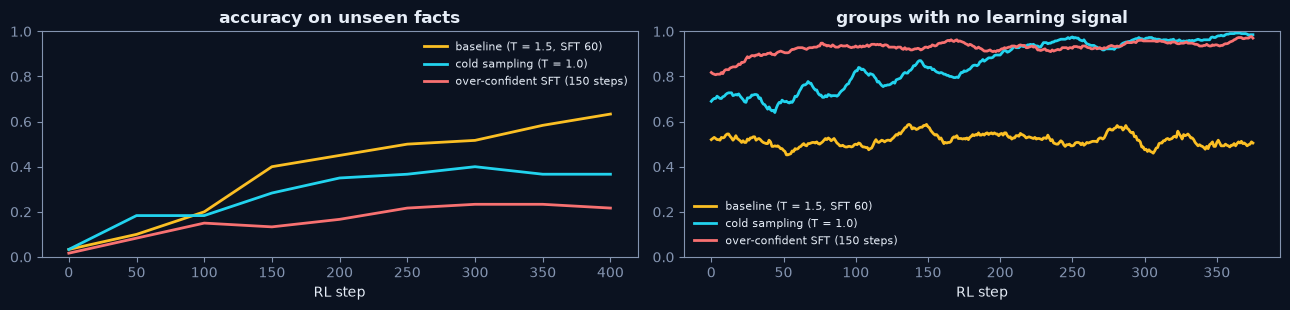

In [12]:
ablations = {
    "baseline (T = 1.5, SFT 60)": {},
    "cold sampling (T = 1.0)": {"rollout": {"temperature": 1.0}},
    "over-confident SFT (150 steps)": {"sft": {"steps": 150}},
}
results = {}
for name, overrides in ablations.items():
    e = OnlineRLExperiment.from_yaml(CONFIGS / "arithmetic_autoregressive.yaml",
                                     overrides={**overrides, "train": {"track_prompts": 0}})
    h = e.run(e.warm_start(), steps=400)
    results[name] = h
    print(f"{name:<32} unseen {h.evals[0]['unseen']:.0%} → {h.evals[-1]['unseen']:.0%} | "
          f"zero-variance groups (first 100 steps) {np.mean(h.series('zero_variance_fraction')[:100]):.0%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for (name, h), colour in zip(results.items(), [COL["unseen"], COL["reward"], COL["bad"]]):
    axes[0].plot([e["step"] for e in h.evals], [e["unseen"] for e in h.evals], color=colour, lw=2, label=name)
    axes[1].plot(smooth(h.series("zero_variance_fraction")), color=colour, lw=2, label=name)
axes[0].set(title="accuracy on unseen facts", xlabel="RL step", ylim=(0, 1)); axes[0].legend(fontsize=8)
axes[1].set(title="groups with no learning signal", xlabel="RL step", ylim=(0, 1)); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Self-reward: online RL with **no labels at all**

Now remove the verifier. **Test-Time RL** (TTRL; Zuo et al., 2025) uses the policy's own consensus as
the label: sample $G$ answers, take the **majority vote** as a pseudo-label, and reward agreement with
it. Nothing external is read, so the model trains purely on its own outputs.

What should we expect? Majority voting is usually *more accurate than a single sample*, so rewarding
agreement can pull the policy toward the majority answer, and the method works when **the majority
is right**. When the majority is wrong, the same mechanism **locks the error in**, because consistency
is all the reward measures. The run below uses the same warm start and changes one line in the YAML
(`reward.type: majority_vote`).

In [13]:
exp_self = OnlineRLExperiment.from_yaml(CONFIGS / "arithmetic_self_reward.yaml")
assert not exp_self.reward().uses_labels
warm_self = copy.deepcopy(warm)

# What does the warm-start policy's majority vote say for every prompt? (16 samples, T = 1.5)
probe = exp_self.trainer(copy.deepcopy(warm))
probe.rollout = probe.rollout.model_copy(update={"group_size": 16})
votes = probe.collect(task.prompts)
initial_majority = dict(zip(task.prompts, MajorityVoteReward.pseudo_labels(votes.completions, 16)))
majority_right = {p: initial_majority[p] == task.answers[p] for p in task.prompts}
print(f"warm-start majority vote is correct on {np.mean(list(majority_right.values())):.0%} of prompts "
      f"(greedy decoding: {base['all']:.0%})")

t0 = time.time()
hist_self = exp_self.run(warm_self)
print(f"self-reward run: {time.time() - t0:.0f}s | rollout reward {np.mean(hist_self.series('reward_mean')[:20]):.2f} → "
      f"{np.mean(hist_self.series('reward_mean')[-20:]):.2f} | accuracy {hist_self.evals[0]['all']:.0%} → "
      f"{hist_self.evals[-1]['all']:.0%}")

warm-start majority vote is correct on 14% of prompts (greedy decoding: 20%)


self-reward run: 21s | rollout reward 0.80 → 0.91 | accuracy 20% → 13%


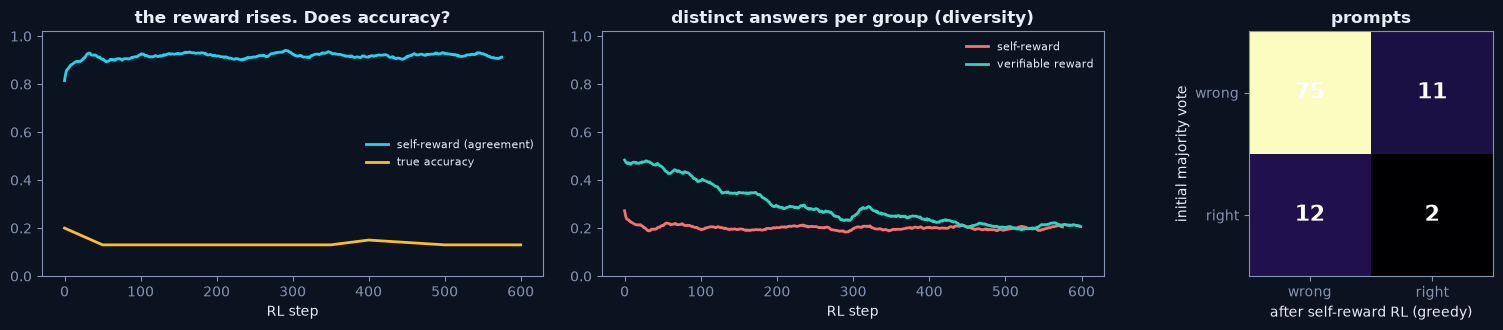

initial majority right: 14 prompts → 2 still right, 12 drifted to a wrong answer
initial majority wrong: 86 prompts → 11 became right, 75 stayed wrong


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
axes[0].plot(smooth(hist_self.series("reward_mean")), color=COL["reward"], lw=2, label="self-reward (agreement)")
steps = [e["step"] for e in hist_self.evals]
axes[0].plot(steps, [e["all"] for e in hist_self.evals], color=COL["unseen"], lw=2, label="true accuracy")
axes[0].set(title="the reward rises. Does accuracy?", xlabel="RL step", ylim=(0, 1.02)); axes[0].legend(fontsize=8)
axes[1].plot(smooth(hist_self.series("unique_answers")) / 8, color=COL["bad"], lw=2, label="self-reward")
axes[1].plot(smooth(hist_ar.series("unique_answers"))[:len(hist_self.stats)] / 8, color=COL["seen"], lw=2,
             label="verifiable reward")
axes[1].set(title="distinct answers per group (diversity)", xlabel="RL step", ylim=(0, 1.02)); axes[1].legend(fontsize=8)

final = dict(zip(task.prompts, exp_self.evaluator.decode(warm_self, task.prompts)))
table = np.zeros((2, 2))
for p in task.prompts:
    table[int(majority_right[p]), int(final[p] == task.answers[p])] += 1
axes[2].imshow(table, cmap="magma")
for (i, j), v in np.ndenumerate(table):
    axes[2].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=16, color="white", weight="bold")
axes[2].set_xticks([0, 1], ["wrong", "right"]); axes[2].set_yticks([0, 1], ["wrong", "right"])
axes[2].set(xlabel="after self-reward RL (greedy)", ylabel="initial majority vote", title="prompts")
plt.tight_layout(); plt.show()
kept = int(table[1, 1]); lost = int(table[1, 0]); fixed = int(table[0, 1]); stuck = int(table[0, 0])
print(f"initial majority right: {kept + lost} prompts → {kept} still right, {lost} drifted to a wrong answer")
print(f"initial majority wrong: {fixed + stuck} prompts → {fixed} became right, {stuck} stayed wrong")

**What happened.** The self-reward climbs toward 1 almost immediately: the model becomes
**self-consistent**, and the diversity of its answers collapses. Accuracy does **not** follow. The table
shows why. On this weak warm start the initial majority vote is wrong for most prompts, and which
answer ends up "consistent" is not tied to the truth: wrong majorities get entrenched, and even some
prompts with a right initial majority drift to a different, wrong consensus. The cell below prints the
exact counts. TTRL's positive results rely on the opposite regime: a base model whose majority vote is
already clearly better than its single samples.

The lesson, matching the TTRL paper's own analysis: **label-free self-reward amplifies the model's
existing beliefs**. It is a strong tool when the base model's majority vote is already better than its
single samples (large models, easy-ish problems), and a trap otherwise. In practice it is combined
with verifiers, held-out checks and early stopping on a labelled dev set.

Below, the same GRPO step animated with the pseudo-label, and the distribution of a prompt whose
initial majority was **wrong** (purple) collapsing onto it.

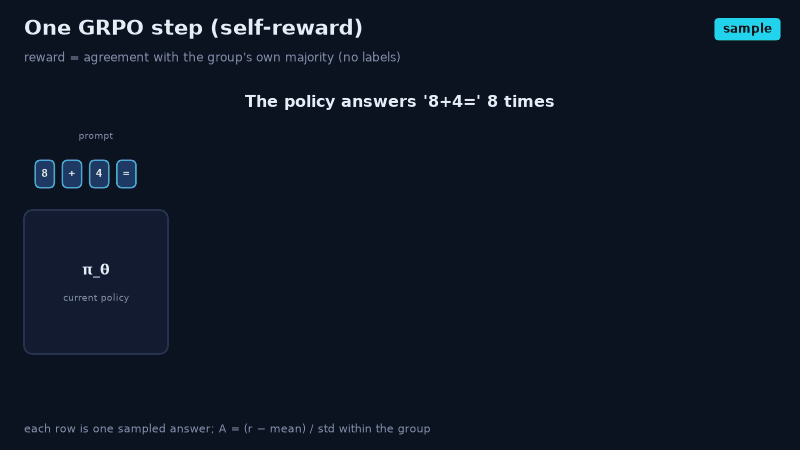

In [15]:
prompt_s, answers_s, rewards_s, adv_s = hist_self.groups[0]
pseudo = MajorityVoteReward.pseudo_labels(answers_s, len(answers_s))[0]
film = GRPOStepFilm(prompt_s, answers_s, rewards_s, adv_s, title="One GRPO step (self-reward)", pseudo_label=pseudo)
display(Image(filename=str(film.render(FILMS / "grpo_step_self_reward.gif")), embed=True))

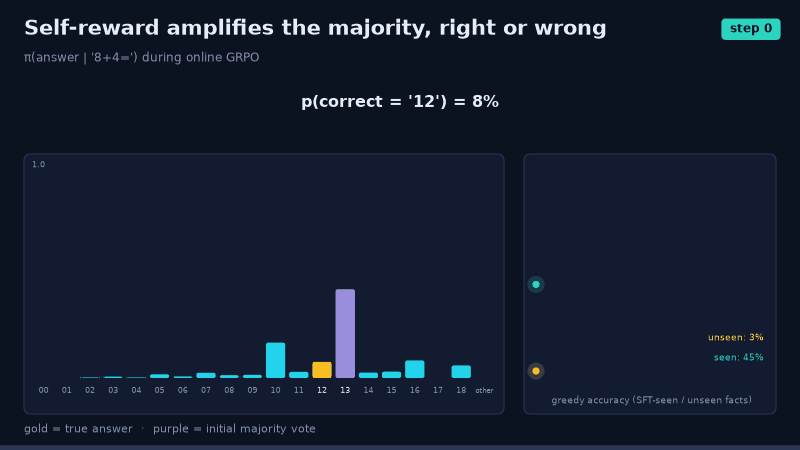

In [16]:
wrong = [p for p in hist_self.tracked_prompts if not majority_right[p]] or hist_self.tracked_prompts
p_show = wrong[0]
film = PolicyEvolutionFilm.from_history(hist_self, p_show, task.answers[p_show], highlight=initial_majority[p_show],
                                        title="Self-reward amplifies the majority, right or wrong")
display(Image(filename=str(film.render(FILMS / "policy_evolution_self_reward.gif")), embed=True))

## 8. Online RL for diffusion LLMs

Everything above needed one number per rollout: $\log\pi_\theta(y\mid x)$. An autoregressive model gives
it **exactly**, in one teacher-forced pass. A **masked-diffusion LM** (this repo's `diffusion` variant)
generates by unmasking tokens in an order chosen at sampling time, so

$$\pi_\theta(y\mid x) = \sum_{\text{unmasking orders}} \;\prod_{\text{steps}} p_\theta(\text{revealed tokens}\mid\text{current mask}),$$

which is **intractable**. **d1 / diffu-GRPO** (Zhao et al., 2025) replaces it with a one-pass
**mean-field estimate**:

1. mask **every** completion token (the state at $t = 1$);
2. also mask a random ~15 % of the **prompt** tokens; this differs per inner epoch, acting as a
   regulariser so one rollout can be reused for several updates;
3. one forward pass; read each completion token's log-probability independently and sum.

The trainer is unchanged. The only new piece is the registered `MaskedDiffusionLogProb` for
`variant: diffusion`, which is the payoff of putting estimators behind an interface.

```mermaid
flowchart LR
  subgraph AR["autoregressive: exact"]
    A1["[x ; y] teacher-forced"] --> A2["1 causal pass"] --> A3["Σ_k log π(y_k | x, y_<k)"]
  end
  subgraph DL["masked diffusion: d1 estimate"]
    D1["[x with ~15% masked ; y all masked]"] --> D2["1 bidirectional pass at t = 1"] --> D3["Σ_k log p(y_k | masked view)"]
  end
```

The animation runs the estimator on the diffusion warm-start model, with three inner-epoch views of
one rollout.

diffusion warm start 2.1s; accuracy 28%
inner epoch 1: masked prompt positions [] → log π̂ = -4.764
inner epoch 2: masked prompt positions [3] → log π̂ = -4.449
inner epoch 3: masked prompt positions [1] → log π̂ = -4.835


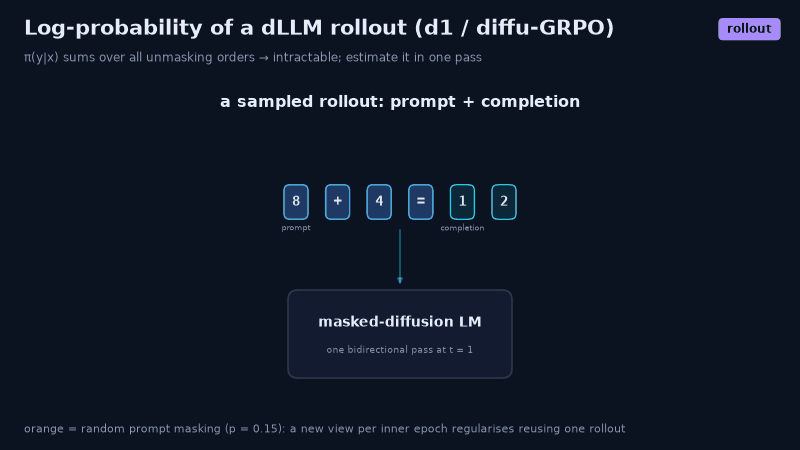

In [17]:
exp_d = OnlineRLExperiment.from_yaml(CONFIGS / "arithmetic_diffusion.yaml")
t0 = time.time()
warm_d = exp_d.warm_start()
print(f"diffusion warm start {time.time() - t0:.1f}s; accuracy {exp_d.evaluate(warm_d, 0)['all']:.0%}")

# Pick the first seed whose three inner-epoch masks differ, so the regularising effect is visible.
for seed in range(50):
    film = DiffusionLogProbFilm.from_model(warm_d, exp_d.tokenizer, prompt0, task.answers[prompt0],
                                           prompt_mask_prob=exp_d.cfg.grpo.prompt_mask_prob, epochs=3, seed=seed)
    if len({v.hidden_prompt for v in film.views}) == 3:
        break
for e, v in enumerate(film.views, 1):
    print(f"inner epoch {e}: masked prompt positions {list(v.hidden_prompt)} → log π̂ = {sum(v.token_logps):.3f}")
display(Image(filename=str(film.render(FILMS / "diffusion_log_prob.gif")), embed=True))

diffu-GRPO: 1500 steps in 68s | accuracy 31% → 63% (unseen 7% → 43%)


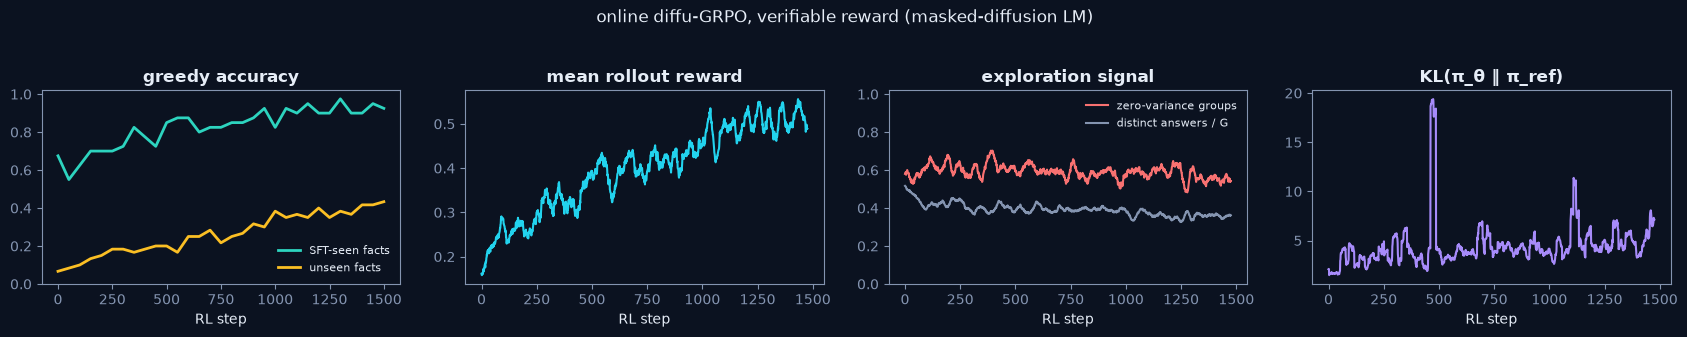

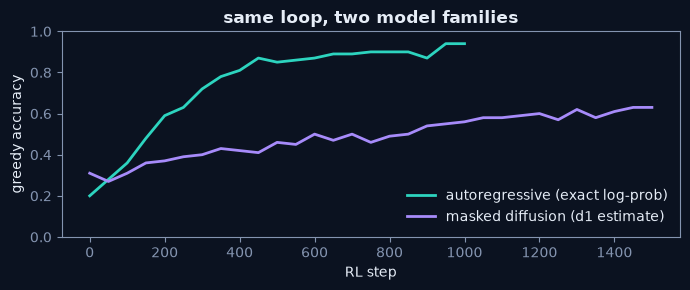

In [18]:
t0 = time.time()
policy_d = copy.deepcopy(warm_d)
hist_d = exp_d.run(policy_d)
print(f"diffu-GRPO: {len(hist_d.stats)} steps in {time.time() - t0:.0f}s | accuracy "
      f"{hist_d.evals[0]['all']:.0%} → {hist_d.evals[-1]['all']:.0%} (unseen {hist_d.evals[0]['unseen']:.0%} → "
      f"{hist_d.evals[-1]['unseen']:.0%})")
curves(hist_d, "online diffu-GRPO, verifiable reward (masked-diffusion LM)")

fig, ax = plt.subplots(figsize=(7, 3))
for h, name, colour in [(hist_ar, "autoregressive (exact log-prob)", COL["seen"]),
                        (hist_d, "masked diffusion (d1 estimate)", "#A78BFA")]:
    ax.plot([e["step"] for e in h.evals], [e["all"] for e in h.evals], color=colour, lw=2, label=name)
ax.set(title="same loop, two model families", xlabel="RL step", ylabel="greedy accuracy", ylim=(0, 1)); ax.legend()
plt.tight_layout(); plt.show()

The diffusion model improves with the very same loop, but more slowly. That is expected from the
mean-field estimate: it scores each answer digit as if the other were unknown, while the sampler can
reveal both digits **in the same step**, so the policy gradient sees a factorised approximation of the
joint it samples from. d1 pairs this estimator with SFT on reasoning traces and much larger models;
follow-ups improve the likelihood estimate (more masks or timesteps per rollout, variance-reduced
ELBO estimators) at extra compute.

## 9. Pitfalls checklist

| symptom | cause | what to do |
|---|---|---|
| reward flat, many **zero-variance groups** | policy never samples a correct (or an incorrect) answer | raise temperature, weaker or more diverse SFT, larger G, curriculum on difficulty |
| reward ↑ but true accuracy ↓ | **reward hacking**: self-reward rewards consistency, a learned RM has exploits | use verifiable rewards where possible; track a labelled dev set; early stop |
| diversity collapses, pass@k drops | entropy collapse from over-sharpening | KL anchor (β), clip ε, entropy bonus, fewer inner epochs |
| unstable or exploding updates | stale ratios (too many inner epochs), too high lr | keep ρ near 1 (clip fraction < ~20 %), smaller lr |
| long answers favoured or penalised | per-sequence length normalisation, std scaling | Dr. GRPO (no std / length normalisation): `normalize_std: false` |
| dLLM learns slowly | noisy one-step log-prob estimate | more inner epochs with fresh prompt masks, better ELBO estimators |

## Summary

* **Online RL** = the model generates its training data from its *current* self, a reward judges it,
  and policy gradients shift probability toward better-than-average samples.
* **GRPO** replaces the critic with a **group baseline**; with clipping and a KL anchor it is the
  workhorse behind recent reasoning models.
* **Exploration is the bottleneck.** A group with no variance teaches nothing, so sampling temperature
  and the confidence of the warm start matter as much as the learning rate.
* **Self-reward** (majority vote) needs no labels but optimises *consistency*. It helps when the
  majority is right and entrenches errors otherwise.
* **Diffusion LLMs** need a log-likelihood estimate (d1's one-pass mean field). With that one plug-in,
  the same trainer works.

**Code:** `src/hale_llm/rl/` (one class per file; registries `REWARDS`, `LOG_PROB_ESTIMATORS`),
`configs/rl/*.yaml`, animations in `src/hale_llm/visualization/rl_films/`, tests in
`tests/unit/test_online_rl.py`.

## References

* R. J. Williams. **Simple statistical gradient-following algorithms for connectionist RL** (REINFORCE). *Machine Learning*, 1992.
* J. Schulman et al. **Proximal Policy Optimization algorithms**, 2017. [arXiv:1707.06347](https://arxiv.org/abs/1707.06347)
* Z. Shao et al. **DeepSeekMath** (introduces GRPO), 2024. [arXiv:2402.03300](https://arxiv.org/abs/2402.03300)
* DeepSeek-AI. **DeepSeek-R1**: incentivizing reasoning capability in LLMs via RL, 2025. [arXiv:2501.12948](https://arxiv.org/abs/2501.12948)
* W. Yuan et al. **Self-Rewarding Language Models**, 2024. [arXiv:2401.10020](https://arxiv.org/abs/2401.10020)
* Y. Zuo et al. **TTRL: Test-Time Reinforcement Learning**, 2025. [arXiv:2504.16084](https://arxiv.org/abs/2504.16084)
* S. Zhao et al. **d1: Scaling reasoning in diffusion LLMs via RL** (diffu-GRPO), 2025. [arXiv:2504.12216](https://arxiv.org/abs/2504.12216)
* J. Schulman. **Approximating KL divergence** (the k1/k2/k3 estimators), blog post, 2020.